# Tarea Hogar 04 — LightGBM, tercera capa + Salsa Mágica

Método de 11 hiperparámetros con ganancia directa, ahora sacando las 2 variables con Data Drifting que encontró Gustavo (`cprestamos_personales`, `mprestamos_personales`) — todo lo demás queda igual.

# Tarea para el Hogar 04

##  1. Big Picture

LightGBM es el algoritmo estado del arte para datasets estructurados.
<br> La Bayesian Optimization es el estado del arte para optimización de hiperparámetros
<br> Las soluciones a las tres competencias de la asignatura contendrán LightGBMs y Bayesian Optimizations
<br> LightGBM ha aumentado en forma no darwiniana sus hiperparámetros en los últimos ocho años; no todos los existentes son útiles.
<br> Es necesario lograr entender cuales son los hiperparámetros relevantes de LightGBM

## 2. Hiperparámetros del LightGBM

Los objetivos de esta tarea son:


*   Aumentar la rentabilidad de la campaña de marketing de retención proactiva de clientes.
*   Generar un mejor modelo optimizando sus hiperparámetros
*   Conceptual : investigar los mas relevantes hiperparámetros de LightGBM
*   Familiarizarse con la Bayesian Optimization, sus largos tiempos de corrida y opciones para reducirlos
*   Familiarizarse con el uso de máquinas virtuales de Google Colab
*   Ver un pipeline completo de optimización de hiperparámetros y puesta en producción

LightGBM cuenta con mas de 60 hiperparámetros, siendo posible utilizar 40 al mismo tiempo, aunque no razonable.
<br> La documentación oficial de los hiperparámetros de LightGBM es  https://lightgbm.readthedocs.io/en/latest/Parameters.html#core-parameters


Se lo alerta sobre que una Optimizacion Bayesiana lleva varias horas de corrida, y usted deberá correr VARIAS optimizaciones para descubrir cuales parámetros conviene optimizar.
<br> A pesar que la próxima clase es recien en viernes 01 de agosto, inicie la tarea con tiempo, aprenda a planificar estratégicamente sus corridas como un@ científ@  de datos.

Es necesario investigar cuales son los hiperparámetros de LightGBM que vale la pena optimizar en una Bayesian Optimization, ya que los realmente utiles son apenas un reducido subconjunto.
<br>Usted deberá investigar cuales son los hiperparámetros mas relevantes de LightGBM, su primer alternativa es preguntándole a su amigo con capacidades especiales ChatGPT o sus endogámicos familiares Claude, DeepSeek, Gemini, Grok, etc
<br> La segunda alternativa es la propia documentación de LightGBM  https://lightgbm.readthedocs.io/en/latest/Parameters-Tuning.html


Adicionalmente podra buscar información como la que proveen esta diminuta muestra aleatoria de artículos ligeros:
*  https://medium.com/@sarahzouinina/a-deep-dive-into-lightgbm-how-to-choose-and-tune-parameters-7c584945842e
*  https://www.kaggle.com/code/somang1418/tuning-hyperparameters-under-10-minutes-lgbm
*  https://towardsdatascience.com/beginners-guide-to-the-must-know-lightgbm-hyperparameters-a0005a812702/


<br>  La muestra anterior se brinda a modo de ejemplo, usted deberá buscar muuuuchas  fuentes adicionales de información
<br> Tenga presente que LightGBM es el estado del arte en modelado predictivo para datasets estructurado, que son el 90% del trabajo del 95% de los Data Scientists en Argentina.

El desafío de esta tarea es:
* Qué hiperparparámetros conviene optimizar?  Las recomendaciones de los artículos ligeros es siempre sensata?  Sus autores realmente hicieron experimentos o son siemplemente escritores de entretenimiento carente de base científica?
* Elegidos los hiperparámetros, cual es el  <desde, hasta> que se debe utilizar en la Bayesian Optimization ?
* Realmente vale la pena optimizar 10 o 16 hiperparámetros al mismo tiempo ?  No resulta contraproducente una búsqueda en un espacio de tal alta dimensionalidad ?

### Seteo del ambiente — versión LOCAL (VSCode + kernel R, sin Google Colab)

Reemplaza el montaje de Google Drive y la descarga por shell script por rutas y un archivo ya descargado localmente. Las rutas quedan en variables aparte (`PARAM_carpeta_datasets`, etc.) para que sobrevivan aunque más abajo el notebook resetee `PARAM` para cada sección nueva.

In [1]:
# rutas locales (variables protegidas, sobreviven a los rm(list=ls()) y a los PARAM <- list() de cada seccion)
PARAM_carpeta_datasets <- "C:/Users/Laura/Documents/DMEyF/datasets/"
PARAM_carpeta_exp      <- "C:/Users/Laura/Documents/DMEyF/exp/"
PARAM_archivo_crudo    <- "C:/Users/Laura/Documents/DMEyF/competencia_01_crudo (1).csv"

dir.create(PARAM_carpeta_datasets, showWarnings = FALSE, recursive = TRUE)
dir.create(PARAM_carpeta_exp, showWarnings = FALSE, recursive = TRUE)

file.exists(PARAM_archivo_crudo)  # tiene que dar TRUE

[1] TRUE

## Generacion de la clase_ternaria

Esta parte se debe correr con el runtime en lenguaje **R** Ir al menu, Runtime -> Change Runtime Tipe -> Runtime type -> R

In [2]:
require( "data.table" )

# leo el dataset
dataset <- fread(PARAM_archivo_crudo)

# calculo el periodo0 consecutivo
dsimple <- dataset[, list(
    "pos" = .I,
    numero_de_cliente,
    periodo0 = as.integer(foto_mes/100)*12 +  foto_mes%%100 ) ]


# ordeno
setorder( dsimple, numero_de_cliente, periodo0 )

# calculo topes
periodo_ultimo <- dsimple[, max(periodo0) ]
periodo_anteultimo <- periodo_ultimo - 1


# calculo los leads de orden 1 y 2
dsimple[, c("periodo1", "periodo2") :=
    shift(periodo0, n=1:2, fill=NA, type="lead"),  numero_de_cliente ]

# assign most common class values = "CONTINUA"
dsimple[ periodo0 < periodo_anteultimo, clase_ternaria := "CONTINUA" ]

# calculo BAJA+1
dsimple[ periodo0 < periodo_ultimo &
    ( is.na(periodo1) | periodo0 + 1 < periodo1 ),
    clase_ternaria := "BAJA+1" ]

# calculo BAJA+2
dsimple[ periodo0 < periodo_anteultimo & (periodo0+1 == periodo1 )
    & ( is.na(periodo2) | periodo0 + 2 < periodo2 ),
    clase_ternaria := "BAJA+2" ]


# pego el resultado en el dataset original y grabo
setorder( dsimple, pos )
dataset[, clase_ternaria := dsimple$clase_ternaria ]

fwrite(
    dataset,
    file = paste0(PARAM_carpeta_datasets, "competencia_01.csv"),
    sep = ","
)

Caricamento del pacchetto richiesto: data.table



In [3]:
setorder( dataset, foto_mes, clase_ternaria, numero_de_cliente)
dataset[, .N, list(foto_mes, clase_ternaria)]

foto_mes,clase_ternaria,N
<int>,<chr>,<int>
202103,BAJA+1,1019
202103,BAJA+2,960
202103,CONTINUA,160921
202104,BAJA+1,964
202104,BAJA+2,1139
202104,CONTINUA,161181
202105,BAJA+1,1143
202105,BAJA+2,870
202105,CONTINUA,161755


### 2.2 Optimizacion Hiperparámetros

Esta parte se debe correr con el runtime en lenguaje R Ir al menu, Runtime -> Change Runtime Type -> Runtime type -> R

### 2.2.1 Inicio

limpio el ambiente de R

In [4]:
format(Sys.time(), "%a %b %d %X %Y")

[1] "gio set 10 06:52:36 2026"

In [5]:
# limpio la memoria
rm(list = setdiff(ls(all.names = TRUE), c("PARAM_carpeta_datasets", "PARAM_carpeta_exp", "PARAM_archivo_crudo"))) # conservo las rutas locales
gc(full=TRUE, verbose=FALSE) # garbage collection

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,724702,38.8,1447537,77.4,1447537,77.4
Vcells,1351959,10.4,170822731,1303.3,212583826,1621.9


### 2.2.2 Carga de Librerias

Esta parte lleva varios minutos la primera vez en Google Colab

In [6]:
# cargo las librerias que necesito
require("data.table")
require("parallel")

if(!require("R.utils")) install.packages("R.utils")
require("R.utils")

if( !require("primes") ) install.packages("primes")
require("primes")

if( !require("utils") ) install.packages("utils")
require("utils")

if( !require("rlist") ) install.packages("rlist")
require("rlist")

if( !require("yaml")) install.packages("yaml")
require("yaml")

if( !require("lightgbm") ) install.packages("lightgbm")
require("lightgbm")

if( !require("DiceKriging") ) install.packages("DiceKriging")
require("DiceKriging")

if( !require("mlrMBO") ) install.packages("mlrMBO")
require("mlrMBO")

Caricamento del pacchetto richiesto: parallel

Caricamento del pacchetto richiesto: R.utils

Caricamento del pacchetto richiesto: R.oo

Caricamento del pacchetto richiesto: R.methodsS3

R.methodsS3 v1.8.2 (2022-06-13 22:00:14 UTC) successfully loaded. See ?R.methodsS3 for help.

R.oo v1.27.1 (2025-05-02 21:00:05 UTC) successfully loaded. See ?R.oo for help.


Caricamento pacchetto: 'R.oo'


Il seguente oggetto è mascherato da 'package:R.methodsS3':

    throw


I seguenti oggetti sono mascherati da 'package:methods':

    getClasses, getMethods


I seguenti oggetti sono mascherati da 'package:base':

    attach, detach, load, save


R.utils v2.13.0 (2025-02-24 21:20:02 UTC) successfully loaded. See ?R.utils for help.


Caricamento pacchetto: 'R.utils'


Il seguente oggetto è mascherato da 'package:utils':

    timestamp


I seguenti oggetti sono mascherati da 'package:base':

    cat, commandArgs, getOption, isOpen, nullfile, parse, use, warnings


Caricamento del pacchetto richiesto: 

### 2.2.3 Definicion de Parametros

aqui debe cargar SU semilla primigenia
<br>recuerde cambiar el numero de experimento en cada corrida nueva

In [7]:
PARAM <- list()
PARAM$carpeta_datasets <- PARAM_carpeta_datasets
PARAM$carpeta_exp      <- PARAM_carpeta_exp
PARAM$experimento <- 4961
PARAM$semilla_primigenia <- 585581


In [8]:
# training y future
PARAM$train <- c(202104)
PARAM$train_final <- c(202104)
PARAM$future <- c(202106)
PARAM$semilla_kaggle <- 314159
PARAM$cortes <- seq(4000, 19000, by= 500)

In [9]:
# un undersampling de 0.1  toma solo el 10% de los CONTINUA
# undersampling de 1.0  implica tomar TODOS los datos

PARAM$trainingstrategy$undersampling <- 0.1

In [10]:
# Parametros LightGBM

PARAM$hyperparametertuning$xval_folds <- 5

# parametros fijos del LightGBM que se pisaran con la parte variable de la BO
PARAM$lgbm$param_fijos <-  list(
  boosting= "gbdt", # puede ir  dart  , ni pruebe random_forest
  objective= "binary",
  metric= "auc",
  first_metric_only= FALSE,
  boost_from_average= TRUE,
  feature_pre_filter= FALSE,
  force_row_wise= TRUE, # para reducir warnings
  verbosity= -100,

  seed= PARAM$semilla_primigenia,

  max_depth= -1L, # -1 significa no limitar,  por ahora lo dejo fijo
  min_gain_to_split= 0, # min_gain_to_split >= 0
  min_sum_hessian_in_leaf= 0.001, #  min_sum_hessian_in_leaf >= 0.0
  lambda_l1= 0.0, # lambda_l1 >= 0.0
  lambda_l2= 0.0, # lambda_l2 >= 0.0
  max_bin= 31L, # lo debo dejar fijo, no participa de la BO

  bagging_fraction= 1.0, # 0.0 < bagging_fraction <= 1.0
  pos_bagging_fraction= 1.0, # 0.0 < pos_bagging_fraction <= 1.0
  neg_bagging_fraction= 1.0, # 0.0 < neg_bagging_fraction <= 1.0
  is_unbalance= FALSE, #
  scale_pos_weight= 1.0, # scale_pos_weight > 0.0

  drop_rate= 0.1, # 0.0 < neg_bagging_fraction <= 1.0
  max_drop= 50, # <=0 means no limit
  skip_drop= 0.5, # 0.0 <= skip_drop <= 1.0

  extra_trees= FALSE,

  num_iterations= 1200,
  learning_rate= 0.02,
  feature_fraction= 0.5,
  num_leaves= 750,
  min_data_in_leaf= 5000
)


Aqui se definen los hiperparámetros de LightGBM que participan de la Bayesian Optimization
<br> si es un numero entero debe ir  makeIntegerParam
<br> si es un numero real (con decimales) debe ir  makeNumericParam
<br> es muy importante leer cuales son un lower y upper  permitidos y ademas razonables

In [11]:
# tercera capa: agrego lambda_l1, lambda_l2, bagging_fraction, bagging_freq (11 hiperparametros en total)
PARAM$hypeparametertuning$hs <- makeParamSet(
  makeIntegerParam("num_iterations", lower= 8L, upper= 2048L),
  makeNumericParam("learning_rate", lower= 0.01, upper= 0.3),
  makeNumericParam("feature_fraction", lower= 0.1, upper= 1.0),
  makeIntegerParam("num_leaves", lower= 8L, upper= 2048L),
  makeIntegerParam("min_data_in_leaf", lower= 1L, upper= 8000L),
  makeNumericParam("scale_pos_weight", lower= 0.1, upper= 50),
  makeNumericParam("min_gain_to_split", lower= 0, upper= 1),
  makeNumericParam("lambda_l1", lower= 0, upper= 10),
  makeNumericParam("lambda_l2", lower= 0, upper= 10),
  makeNumericParam("bagging_fraction", lower= 0.1, upper= 1.0),
  makeIntegerParam("bagging_freq", lower= 0L, upper= 10L)
)

A mayor cantidad de hiperparámetros, se debe aumentar las iteraciones de la Bayesian Optimization
<br> 30 es un valor muy tacaño, pero corre rápido
<br> deberia partir de 50, alcanzando los 100 si se dispone de tiempo

In [12]:
PARAM$hyperparametertuning$iteraciones <- 100 # subo proporcional (7->11 hiperparametros), redondeado por tiempo

In [13]:
# particionar agrega una columna llamada fold a un dataset
#   que consiste en una particion estratificada segun agrupa
# particionar( data=dataset, division=c(70,30),
#  agrupa=clase_ternaria, seed=semilla)   crea una particion 70, 30

particionar <- function(data, division, agrupa= "", campo= "fold", start= 1, seed= NA) {
  if (!is.na(seed)) set.seed(seed, "L'Ecuyer-CMRG")

  bloque <- unlist(mapply(
    function(x, y) {rep(y, x)},division, seq(from= start, length.out= length(division))))

  data[, (campo) := sample(rep(bloque,ceiling(.N / length(bloque))))[1:.N],by= agrupa]
}

In [14]:
# iniciliazo el dataset de realidad, para medir ganancia
realidad_inicializar <- function( pfuture, pparam) {

  # datos para verificar la ganancia
  drealidad <- pfuture[, list(numero_de_cliente, foto_mes, clase_ternaria)]

  particionar(drealidad,
    division= c(3, 7),
    agrupa= "clase_ternaria",
    seed= PARAM$semilla_kaggle
  )

  return( drealidad )
}

In [15]:
# evaluo ganancia en los datos de la realidad

realidad_evaluar <- function( prealidad, pprediccion) {

  prealidad[ pprediccion,
    on= c("numero_de_cliente", "foto_mes"),
    predicted:= i.Predicted
  ]

  tbl <- prealidad[, list("qty"=.N), list(fold, predicted, clase_ternaria)]

  res <- list()
  res$public  <- tbl[fold==1 & predicted==1L, sum(qty*ifelse(clase_ternaria=="BAJA+2", 1072500, -27500))]/0.3
  res$private <- tbl[fold==2 & predicted==1L, sum(qty*ifelse(clase_ternaria=="BAJA+2", 1072500, -27500))]/0.7
  res$total <- tbl[predicted==1L, sum(qty*ifelse(clase_ternaria=="BAJA+2", 1072500, -27500))]

  prealidad[, predicted:=NULL]
  return( res )
}

### 2.2.4  Preprocesamiento

In [16]:
# carpeta de trabajo

setwd(PARAM$carpeta_exp)
experimento_folder <- paste0("HT", PARAM$experimento)
dir.create(experimento_folder, showWarnings=FALSE)
setwd( paste0(PARAM$carpeta_exp, experimento_folder ))

In [17]:
# lectura del dataset
dataset <- fread(paste0(PARAM$carpeta_datasets, "competencia_01.csv"), stringsAsFactors= TRUE)

In [18]:
dataset_train <- dataset[foto_mes %in% PARAM$train]

In [19]:
# paso la clase a binaria que tome valores {0,1}  enteros
#  BAJA+1 y BAJA+2  son  1,   CONTINUA es 0
#  a partir de ahora ya NO puedo cortar  por prob(BAJA+2) > 1/40

dataset_train[,
  clase01 := ifelse(clase_ternaria %in% c("BAJA+2","BAJA+1"), 1L, 0L)
]

In [20]:
# defino los datos que forma parte del training
# aqui se hace el undersampling de los CONTINUA
# notar que para esto utilizo la SEGUNDA semilla

set.seed(PARAM$semilla_primigenia, kind = "L'Ecuyer-CMRG")
dataset_train[, azar := runif(nrow(dataset_train))]
dataset_train[, training := 0L]

dataset_train[
  foto_mes %in%  PARAM$train &
    (azar <= PARAM$trainingstrategy$undersampling | clase_ternaria %in% c("BAJA+1", "BAJA+2")),
  training := 1L
]

In [21]:
# los campos que se van a utilizar

campos_buenos <- setdiff(
  colnames(dataset_train),
  c("clase_ternaria", "clase01", "azar", "training")
)

# Salsa Magica (de Gustavo): saco las 2 variables con Data Drifting entre 202104 y 202106
campos_buenos <- setdiff(campos_buenos, c("cprestamos_personales", "mprestamos_personales"))

In [22]:
# peso por fila: compensa el undersampling de CONTINUA (10% muestreado -> peso 10)
# BAJA+1 y BAJA+2 no se undersamplean, quedan con peso 1
dataset_train[, peso := ifelse(clase_ternaria == "CONTINUA", 1 / PARAM$trainingstrategy$undersampling, 1.0)]

dtrain <- lgb.Dataset(
  data= data.matrix(dataset_train[training == 1L, campos_buenos, with= FALSE]),
  label= dataset_train[training == 1L, clase01],
  weight= dataset_train[training == 1L, peso],
  free_raw_data= FALSE
)

nrow(dtrain)
ncol(dtrain)

[1] 18321

[1] 152

2.2.5 Configuracion Bayesian Optimization

In [23]:
# funcion de ganancia economica para usar como metric= "custom" en lgb.cv
# los pesos ya vienen del dataset (compensan el undersampling)
fganancia_lgbm_binaria <- function(probs, datos) {
  vlabels <- get_field(datos, "label")
  vpesos  <- get_field(datos, "weight")

  gan <- ifelse(probs > 0.025 & vlabels == 1, 1072500 * vpesos,
          ifelse(probs > 0.025 & vlabels == 0, -27500 * vpesos, 0))

  return(list(
    name = "ganancia",
    value = sum(gan),
    higher_better = TRUE
  ))
}

In [24]:
EstimarGanancia_ganancia_lightgbm <- function(x) {

  param_completo <- modifyList(PARAM$lgbm$param_fijos, x)
  param_completo$metric <- "custom"  # uso la funcion de ganancia, no auc

  # entreno LightGBM con cross validation, evaluando con la ganancia economica
  modelocv <- lgb.cv(
    data= dtrain,
    nfold= PARAM$hyperparametertuning$xval_folds,
    stratified= TRUE,
    param= param_completo,
    eval= fganancia_lgbm_binaria
  )

  # obtengo la ganancia (higher_better=TRUE, entonces best_score es el maximo)
  ganancia <- modelocv$best_score

  # hago espacio en la memoria
  rm(modelocv)
  gc(full= TRUE, verbose= FALSE)

  message(format(Sys.time(), "%a %b %d %X %Y"), " ganancia ", ganancia)

  return(ganancia)
}

In [25]:
# Aqui comienza la configuracion de la Bayesian Optimization

# en este archivo quedan la evolucion binaria de la BO
kbayesiana <- "bayesiana.RDATA"

funcion_optimizar <- EstimarGanancia_ganancia_lightgbm # la funcion que voy a maximizar

configureMlr(show.learner.output= FALSE)

# configuro la busqueda bayesiana,  los hiperparametros que se van a optimizar
# por favor, no desesperarse por lo complejo

obj.fun <- makeSingleObjectiveFunction(
  fn= funcion_optimizar, # la funcion que voy a maximizar
  minimize= FALSE, # estoy Maximizando la ganancia
  noisy= TRUE,
  par.set= PARAM$hypeparametertuning$hs, # definido al comienzo del programa
  has.simple.signature= FALSE # paso los parametros en una lista
)

# cada 600 segundos guardo el resultado intermedio
ctrl <- makeMBOControl(
  save.on.disk.at.time= 600, # se graba cada 600 segundos
  save.file.path= kbayesiana
) # se graba cada 600 segundos

# indico la cantidad de iteraciones que va a tener la Bayesian Optimization
ctrl <- setMBOControlTermination(
  ctrl,
  iters= PARAM$hyperparametertuning$iteraciones
) # cantidad de iteraciones

# defino el método estandar para la creacion de los puntos iniciales,
# los "No Inteligentes"
ctrl <- setMBOControlInfill(ctrl, crit= makeMBOInfillCritEI())

# establezco la funcion que busca el maximo
surr.km <- makeLearner(
  "regr.km",
  predict.type= "se",
  covtype= "matern3_2",
  control= list(trace= TRUE)
)


2.2.6 Corrida Bayesian Optimization

In [26]:

# inicio la optimizacion bayesiana, retomando si ya existe
# es la celda mas lenta de todo el notebook

if (!file.exists(kbayesiana)) {
  bayesiana_salida <- mbo(obj.fun, learner= surr.km, control= ctrl)
} else {
  bayesiana_salida <- mboContinue(kbayesiana) # retomo en caso que ya exista
}

Computing y column(s) for design. Not provided.

gio set 10 06:52:50 2026 ganancia 0

gio set 10 06:53:04 2026 ganancia 0

gio set 10 06:53:19 2026 ganancia -10092500

gio set 10 06:53:30 2026 ganancia -20454500

gio set 10 06:53:36 2026 ganancia -88335500

gio set 10 06:53:42 2026 ganancia 0

gio set 10 06:54:05 2026 ganancia 69558500

gio set 10 06:54:08 2026 ganancia 0

gio set 10 06:54:14 2026 ganancia 0

gio set 10 06:54:17 2026 ganancia 16830000

gio set 10 06:54:30 2026 ganancia 81900500

gio set 10 06:54:44 2026 ganancia 0

gio set 10 06:54:55 2026 ganancia 0

gio set 10 06:55:04 2026 ganancia 0

gio set 10 06:55:15 2026 ganancia 109224500

gio set 10 06:55:31 2026 ganancia 12386000

gio set 10 06:55:38 2026 ganancia 0

gio set 10 06:55:55 2026 ganancia -58140500

gio set 10 06:56:00 2026 ganancia 19585500

gio set 10 06:56:19 2026 ganancia -48262500

gio set 10 06:56:45 2026 ganancia 140723000

gio set 10 06:56:52 2026 ganancia 0

gio set 10 06:57:09 2026 ganancia 0

gio set 1

In [27]:

tb_bayesiana <- as.data.table(bayesiana_salida$opt.path)
colnames( tb_bayesiana)

[1] "num_iterations"    "learning_rate"     "feature_fraction" 
 [4] "num_leaves"        "min_data_in_leaf"  "scale_pos_weight" 
 [7] "min_gain_to_split" "lambda_l1"         "lambda_l2"        
[10] "bagging_fraction"  "bagging_freq"      "y"                
[13] "dob"               "eol"               "error.message"    
[16] "exec.time"         "ei"                "error.model"      
[19] "train.time"        "prop.type"         "propose.time"     
[22] "se"                "mean"

In [28]:
# almaceno los resultados de la Bayesian Optimization
# y capturo los mejores hiperparametros encontrados

tb_bayesiana <- as.data.table(bayesiana_salida$opt.path)

tb_bayesiana[, iter := .I]

# ordeno en forma descendente por AUC = y
setorder(tb_bayesiana, -y)

# grabo para eventualmente poder utilizarlos en OTRA corrida
fwrite( tb_bayesiana,
  file= "BO_log.txt",
  sep= "\t"
)

# los mejores hiperparámetros son los que quedaron en el registro 1 de la tabla
PARAM$out$lgbm$mejores_hiperparametros <- tb_bayesiana[
  1, # el primero es el de mejor AUC
  setdiff(colnames(tb_bayesiana),
    c("y","dob","eol","error.message","exec.time","ei","error.model",
      "train.time","prop.type","propose.time","se","mean","iter")),
  with= FALSE
]


PARAM$out$lgbm$y <- tb_bayesiana[1, y]


In [29]:
write_yaml( PARAM, file="PARAM.yml")

In [30]:
print(PARAM$out$lgbm$mejores_hiperparametros)
print(PARAM$out$lgbm$y)

   num_iterations learning_rate feature_fraction num_leaves min_data_in_leaf
            <int>         <num>            <num>      <int>            <int>
1:           1351    0.05475002        0.5153582       1601                1
   scale_pos_weight min_gain_to_split lambda_l1 lambda_l2 bagging_fraction
              <num>             <num>     <num>     <num>            <num>
1:        0.9712104         0.2654667   3.26227  7.540213        0.8329823
   bagging_freq
          <int>
1:            5
[1] 256245000


## 2.3  Produccion

### Final Training
Construyo el modelo final, que es uno solo, no hace ningun tipo de particion < training, validation, testing>]

In [31]:
setwd(PARAM$carpeta_exp)
experimento <- paste0("exp", PARAM$experimento)
dir.create(experimento, showWarnings= FALSE)
setwd( paste0(PARAM$carpeta_exp, experimento ))

#### Final Training Dataset

Aqui esta la gran decision de en qué meses hago el Final Training
<br> debo utilizar los mejores hiperparámetros que encontré en la  optimización bayesiana

In [32]:
# clase01
dataset[, clase01 := ifelse(clase_ternaria %in% c("BAJA+1", "BAJA+2"), 1L, 0L)]

In [33]:
dataset_train <- dataset[foto_mes %in% PARAM$train_final]
dataset_train[,.N,clase_ternaria]

clase_ternaria,N
<fct>,<int>
CONTINUA,161181
BAJA+2,1139
BAJA+1,964


In [34]:
# dejo los datos en el formato que necesita LightGBM

dtrain_final <- lgb.Dataset(
  data= data.matrix(dataset_train[, campos_buenos, with= FALSE]),
  label= dataset_train[, clase01]
)

#### Final Training Hyperparameters

In [35]:
param_final <- modifyList(PARAM$lgbm$param_fijos,
  PARAM$out$lgbm$mejores_hiperparametros)

param_final

$boosting
[1] "gbdt"

$objective
[1] "binary"

$metric
[1] "auc"

$first_metric_only
[1] FALSE

$boost_from_average
[1] TRUE

$feature_pre_filter
[1] FALSE

$force_row_wise
[1] TRUE

$verbosity
[1] -100

$seed
[1] 585581

$max_depth
[1] -1

$min_gain_to_split
[1] 0.2654667

$min_sum_hessian_in_leaf
[1] 0.001

$lambda_l1
[1] 3.26227

$lambda_l2
[1] 7.540213

$max_bin
[1] 31

$bagging_fraction
[1] 0.8329823

$pos_bagging_fraction
[1] 1

$neg_bagging_fraction
[1] 1

$is_unbalance
[1] FALSE

$scale_pos_weight
[1] 0.9712104

$drop_rate
[1] 0.1

$max_drop
[1] 50

$skip_drop
[1] 0.5

$extra_trees
[1] FALSE

$num_iterations
[1] 1351

$learning_rate
[1] 0.05475002

$feature_fraction
[1] 0.5153582

$num_leaves
[1] 1601

$min_data_in_leaf
[1] 1

$bagging_freq
[1] 5

#### Training
Genero el modelo final, siempre sobre TODOS los datos de  final_train, sin hacer ningun tipo de undersampling de la clase mayoritaria y mucho menos cross validation.

In [36]:
# este punto es muy SUTIL  y será revisado en la Clase 05

param_normalizado <- copy(param_final)
param_normalizado$min_data_in_leaf <-  round(param_final$min_data_in_leaf / PARAM$trainingstrategy$undersampling)

In [37]:
# entreno LightGBM

modelo_final <- lgb.train(
  data= dtrain_final,
  param= param_normalizado
)

In [38]:
# ahora imprimo la importancia de variables

tb_importancia <- as.data.table(lgb.importance(modelo_final))
archivo_importancia <- "impo.txt"

fwrite(tb_importancia,
  file= archivo_importancia,
  sep= "\t"
)

In [39]:
# grabo a disco el modelo en un formato para seres humanos ... ponele ...
lgb.save(modelo_final, "modelo.txt" )

### Scoring

Aplico el modelo final a los datos del futuro

In [40]:
# aplico el modelo a los datos sin clase
dfuture <- dataset[foto_mes %in% PARAM$future]

# aplico el modelo a los datos nuevos
prediccion <- predict(
  modelo_final,
  data.matrix(dfuture[, campos_buenos, with= FALSE])
)

#### Tabla Prediccion

In [41]:
# tabla de prediccion
tb_prediccion <- dfuture[, list(numero_de_cliente, foto_mes,clase_ternaria)]
tb_prediccion[, prob := prediccion ]

# grabo las probabilidad del modelo
fwrite(tb_prediccion[,list(numero_de_cliente,foto_mes,prob)],
  file= "prediccion.txt",
  sep= "\t"
)

In [42]:
# Dibujo la curva de ganancia acumulada
setorder(tb_prediccion,-prob)

tb_prediccion[, gan := ifelse(clase_ternaria == "BAJA+2", 1072500, -27500)]
tb_prediccion[, ganancia_acumulada := cumsum(gan)]
tb_prediccion[, pos := sequence(.N)]

In [43]:
tb_prediccion |> head()

numero_de_cliente,foto_mes,clase_ternaria,prob,gan,ganancia_acumulada,pos
<dbl>,<int>,<fct>,<dbl>,<dbl>,<dbl>,<int>
39633412,202106,BAJA+1,0.9477992,-27500,-27500,1
28793962,202106,CONTINUA,0.9464487,-27500,-55000,2
57013533,202106,CONTINUA,0.9415303,-27500,-82500,3
54835556,202106,BAJA+1,0.9328535,-27500,-110000,4
30227609,202106,BAJA+2,0.9180044,1072500,962500,5
33517065,202106,CONTINUA,0.9077485,-27500,935000,6


In [44]:
# defino hasta donde muestra el grafico
amostrar <- 30000

In [45]:
require("ggplot2")

Caricamento del pacchetto richiesto: ggplot2



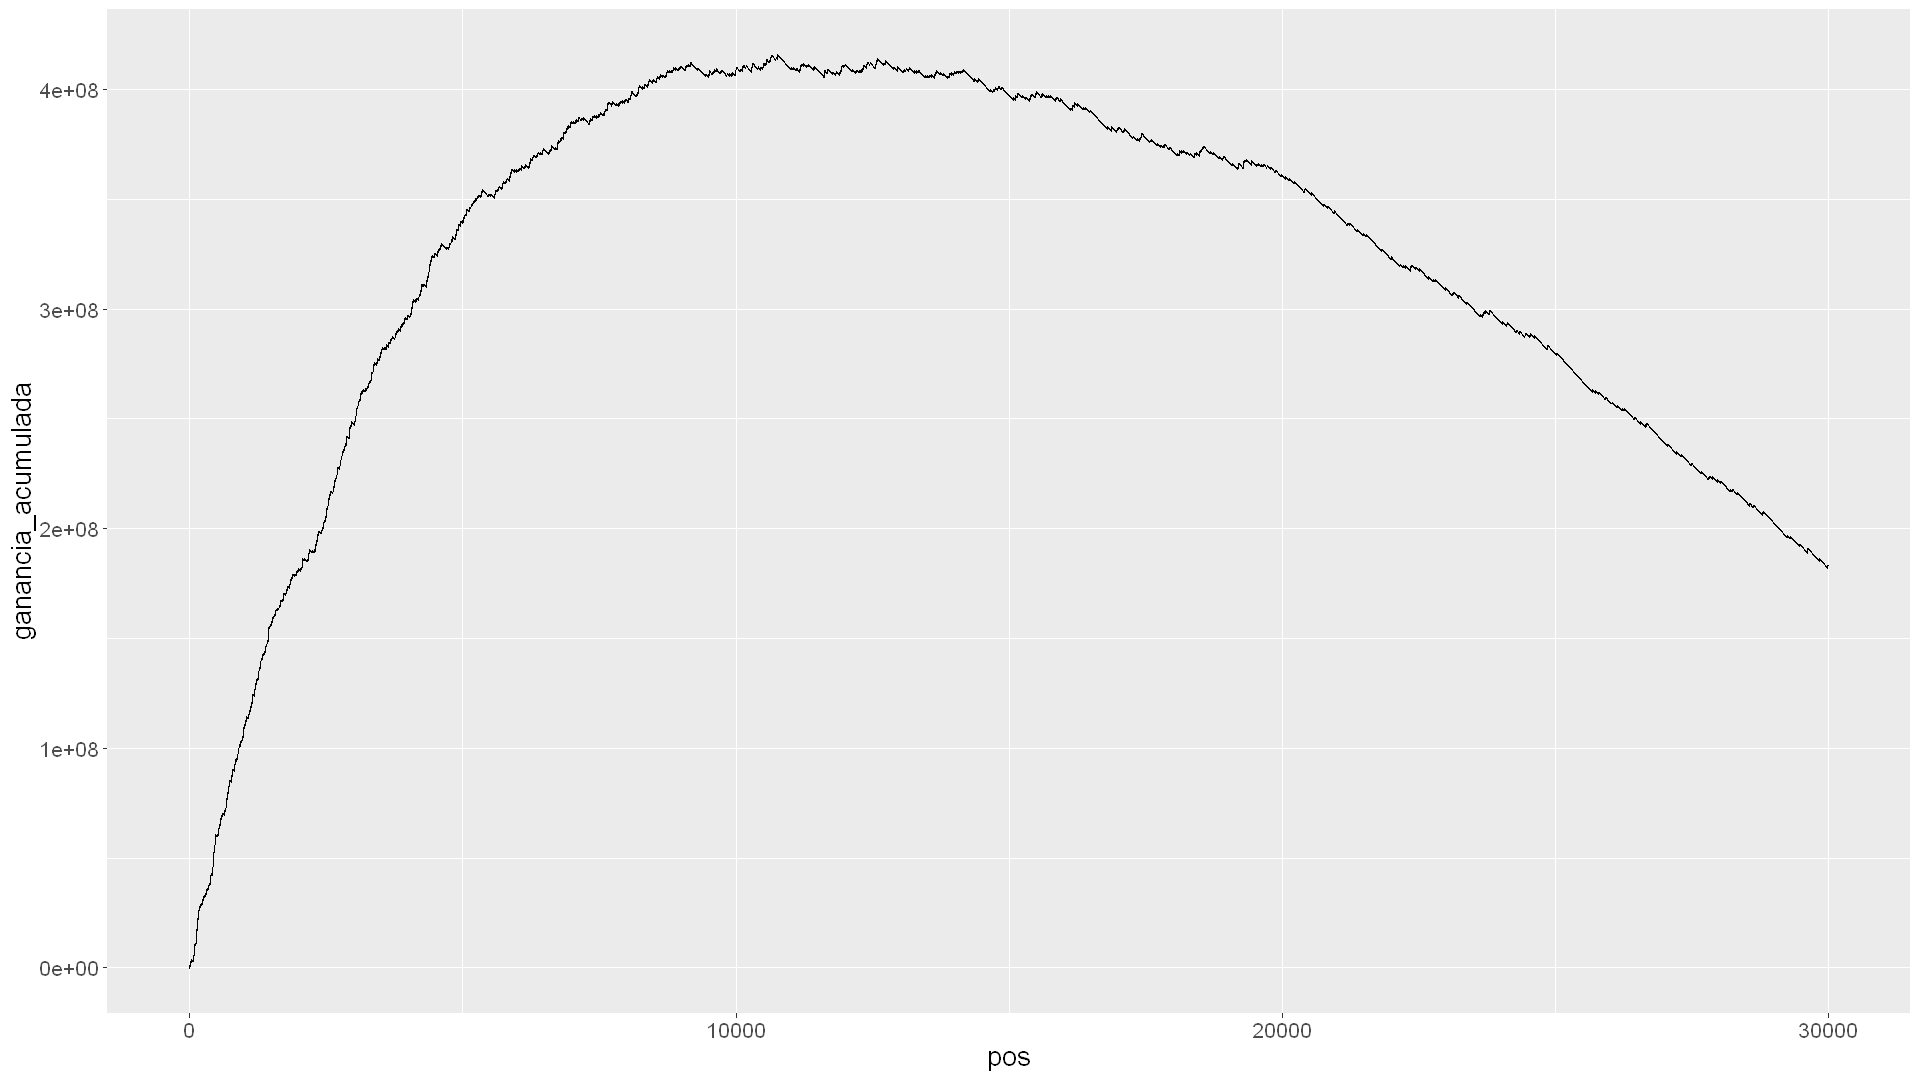

In [46]:
# observamos la curva de ganancia
gra <- ggplot(
           data= tb_prediccion[pos <= amostrar],
           aes( x= pos, y= ganancia_acumulada)
             ) + geom_line()

gra <- gra + theme(text = element_text(size = 16))

options(repr.plot.width=16, repr.plot.height=9)
print( gra )

Revisamos ganancia bajo distintos cortes

In [47]:
# inicilizo el dataset  drealidad
drealidad <- realidad_inicializar( dfuture, PARAM)

In [48]:
PARAM$cortes

[1]  4000  4500  5000  5500  6000  6500  7000  7500  8000  8500  9000  9500
[13] 10000 10500 11000 11500 12000 12500 13000 13500 14000 14500 15000 15500
[25] 16000 16500 17000 17500 18000 18500 19000

In [49]:
# genero archivos con los  "envios" mejores
# suba TODOS los archivos a Kaggle

# ordeno por probabilidad descendente
setorder(tb_prediccion, -prob)

for (envios in PARAM$cortes) {

  tb_prediccion[, Predicted := 0L] # seteo inicial a 0
  tb_prediccion[1:envios, Predicted := 1L] # marco los primeros

  res <- realidad_evaluar( drealidad, tb_prediccion)

  options(scipen = 999)
  cat( "Envios=", envios, "\t",
    " TOTAL=", res$total,
    "  Public=", res$public,
    " Private=", res$private,
    "\n",
    sep= ""
  )

}

Envios=4000	 TOTAL=297000000  Public=308825000 Private=291932143
Envios=4500	 TOTAL=325050000  Public=341733333 Private=317900000
Envios=5000	 TOTAL=339900000  Public=363641667 Private=329725000
Envios=5500	 TOTAL=351450000  Public=367583333 Private=344535714
Envios=6000	 TOTAL=363000000  Public=387016667 Private=352707143
Envios=6500	 TOTAL=372350000  Public=415341667 Private=353925000
Envios=7000	 TOTAL=385000000  Public=419466667 Private=370228571
Envios=7500	 TOTAL=387750000  Public=415983333 Private=375650000
Envios=8000	 TOTAL=394900000  Public=413508333 Private=386925000
Envios=8500	 TOTAL=404250000  Public=431291667 Private=392660714
Envios=9000	 TOTAL=410300000  Public=433583333 Private=400321429
Envios=9500	 TOTAL=406450000  Public=431658333 Private=395646429
Envios=10000	 TOTAL=409200000  Public=446325000 Private=393289286
Envios=10500	 TOTAL=410850000  Public=458150000 Private=390578571
Envios=11000	 TOTAL=409200000  Public=466583333 Private=384607143
Envios=11500	 TOTAL=40

In [50]:
write_yaml( PARAM, file="PARAM.yml")

In [51]:
format(Sys.time(), "%a %b %d %X %Y")

[1] "gio set 10 09:00:20 2026"

Finalmente usted deberá cargar el resultado de su corrida en la Google Sheet Colaborativa,  hoja **TareaHogar04**
<br> Siéntase libre de agregar las columnas que hagan falta a la planilla